#### 💡 Global Alcohol Consumption & Socioeconomic Study
#### 03: Comprehensive Solutions, Policy Frameworks & Executive Insights

- This final phase translates our exploratory findings into concrete business and public health frameworks, risk segmentation matrices, comparative regional analyses, and automated stakeholder reporting without relying on complex machine learning algorithms.



### ⚙️ Environment Setup & Data Ingestion

In [1]:
# Import required analytics and visualization libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visualization aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Load dataset
try:
    df = pd.read_csv('../data/dataset.csv')
except FileNotFoundError:
    df = pd.read_csv('global_alcohol_dataset.csv')

print(f"✅ Dataset loaded successfully: {df.shape[0]} countries, {df.shape[1]} features.")
df.head()

✅ Dataset loaded successfully: 135 countries, 6 features.


,country,alcperpeson,gdppercapita,distancekm,beveragepriceindex,religion
0,Egypt,0.36,2444.29,3002,77.61,1
1,Iraq,0.39,4985.45,3669,133.49,0
2,Bhutan,0.43,3286.60,3057,94.28,1
3,Djibouti,0.43,2926.15,1351,182.91,1
4,Indonesia,0.57,3837.58,558,183.24,0


---

### 🏆 1. Benchmark Analysis: Extreme Performers
To establish baseline targets for policy interventions, we analyze the top 5 highest consumers and bottom 5 lowest consumers alongside their economic indicators.

In [2]:
# Top 5 Highest vs Bottom 5 Lowest Consumers
top_5 = df.nlargest(5, 'alcperpeson')[['country', 'alcperpeson', 'gdppercapita', 'beveragepriceindex']]
bottom_5 = df.nsmallest(5, 'alcperpeson')[['country', 'alcperpeson', 'gdppercapita', 'beveragepriceindex']]

print("--- Top 5 Highest Alcohol Consuming Nations --- waterfowl benchmarks")
display(top_5)

print(
    "\n--- Bottom 5 Lowest Alcohol Consuming Nations --- baseline benchmarks"
)
display(bottom_5)

--- Top 5 Highest Alcohol Consuming Nations --- waterfowl benchmarks


,country,alcperpeson,gdppercapita,beveragepriceindex
134,Seychelles,20.50,16416.70,223.31
133,Uganda,15.09,746.83,96.79
132,Lithuania,13.22,16885.40,81.74
131,Luxembourg,12.94,110193.00,82.67
130,Germany,12.91,44652.60,77.50



--- Bottom 5 Lowest Alcohol Consuming Nations --- baseline benchmarks


,country,alcperpeson,gdppercapita,beveragepriceindex
0,Egypt,0.36,2444.29,77.61
1,Iraq,0.39,4985.45,133.49
2,Bhutan,0.43,3286.60,94.28
3,Djibouti,0.43,2926.15,182.91
4,Indonesia,0.57,3837.58,183.24


---

### 🎯 2. Risk Tier Segmentation Framework
We segment countries into actionable risk tiers (Low Risk, Moderate Risk, and High Risk) based on annual alcohol consumption per person to prioritize health and regulatory interventions.

--- Strategic Risk Tier Summary ---


,risk_tier,country_count,mean_alc,mean_gdp,mean_price_index
0,1. Low Risk (< 3L),31,1.423871,7618.257097,145.977419
1,2. Moderate Risk (3L - 9L),59,6.174237,10085.831695,115.915593
2,3. High Risk (> 9L),45,11.380000,25420.263111,108.429778


C:\Users\Admin\AppData\Local\Temp\ipykernel_23716\2232268584.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='risk_tier', palette='Set2', order=['1. Low Risk (< 3L)', '2. Moderate Risk (3L - 9L)', '3. High Risk (> 9L)'])


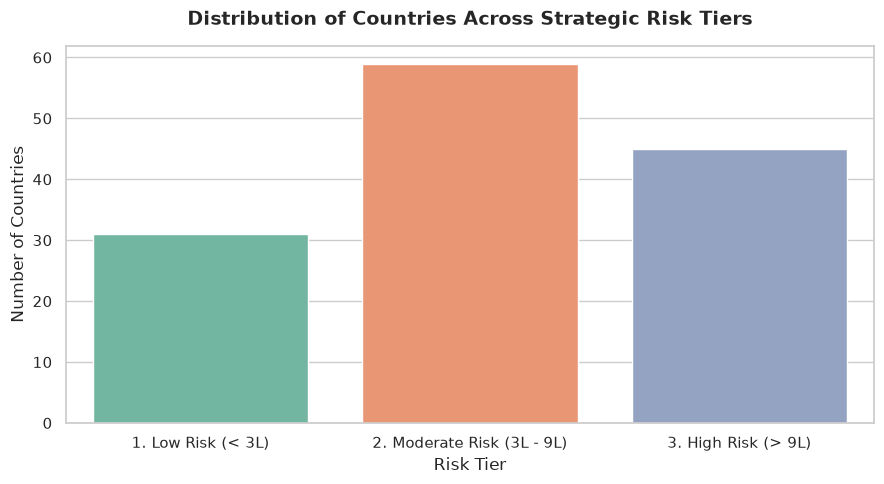

In [3]:
# Define risk tier categorization logic
def categorize_risk(alc):
    if alc < 3.0:
        return '1. Low Risk (< 3L)'
    elif alc <= 9.0:
        return '2. Moderate Risk (3L - 9L)'
    else:
        return '3. High Risk (> 9L)'

df['risk_tier'] = df['alcperpeson'].apply(categorize_risk)

# Summarize risk tiers
tier_summary = df.groupby('risk_tier').agg(
    country_count=('country', 'count'),
    mean_alc=('alcperpeson', 'mean'),
    mean_gdp=('gdppercapita', 'mean'),
    mean_price_index=('beveragepriceindex', 'mean')
).reset_index()

print("--- Strategic Risk Tier Summary ---")
display(tier_summary)

# Visualization 1: Count of countries per risk tier
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x='risk_tier', palette='Set2', order=['1. Low Risk (< 3L)', '2. Moderate Risk (3L - 9L)', '3. High Risk (> 9L)'])
plt.title('Distribution of Countries Across Strategic Risk Tiers', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Risk Tier', fontsize=12)
plt.ylabel('Number of Countries', fontsize=12)
plt.tight_layout()
plt.show()

---

### 📊 3. Socioeconomic & Demographic Policy Matrix (Visualization 2)
Evaluating aggregate metrics grouped by the religious demographic factor to guide tailored economic and community public health policies.

--- Strategic Policy Matrix by Religion Demographic Factor ---


,religion,total_countries,mean_alc,median_alc,mean_gdp,mean_price_index
0,0,82,7.724390,7.985,18015.246585,116.065488
1,1,53,5.417358,4.780,9394.182264,126.911132


C:\Users\Admin\AppData\Local\Temp\ipykernel_23716\448695946.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=policy_matrix, x='religion', y='mean_alc', ax=axes[0], palette='Blues_d')
C:\Users\Admin\AppData\Local\Temp\ipykernel_23716\448695946.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=policy_matrix, x='religion', y='mean_price_index', ax=axes[1], palette='Oranges_d')


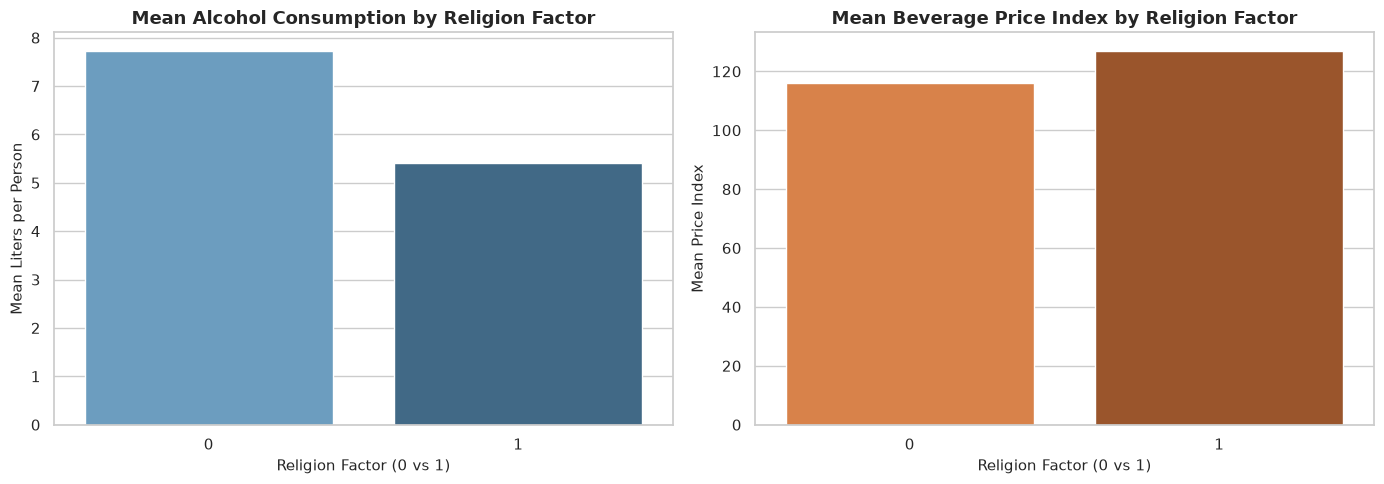

In [4]:
# Demographic Policy Pivot Table
policy_matrix = df.groupby('religion').agg(
    total_countries=('country', 'count'),
    mean_alc=('alcperpeson', 'mean'),
    median_alc=('alcperpeson', 'median'),
    mean_gdp=('gdppercapita', 'mean'),
    mean_price_index=('beveragepriceindex', 'mean')
).reset_index()

print("--- Strategic Policy Matrix by Religion Demographic Factor ---")
display(policy_matrix)

# Visualization 2: Side-by-side bar comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=policy_matrix, x='religion', y='mean_alc', ax=axes[0], palette='Blues_d')
axes[0].set_title('Mean Alcohol Consumption by Religion Factor', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Religion Factor (0 vs 1)', fontsize=11)
axes[0].set_ylabel('Mean Liters per Person', fontsize=11)

sns.barplot(data=policy_matrix, x='religion', y='mean_price_index', ax=axes[1], palette='Oranges_d')
axes[1].set_title('Mean Beverage Price Index by Religion Factor', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Religion Factor (0 vs 1)', fontsize=11)
axes[1].set_ylabel('Mean Price Index', fontsize=11)

plt.tight_layout()
plt.show()

---

### 💡 4. Strategic Recommendations & Action Framework
Based on descriptive findings, pricing distributions, and demographic segmentations, we propose three core pillars for institutional decision-making:

1. **Tiered Excise Taxation & Pricing Regulation:**
   * *Observation:* High-risk tier nations exhibit distinct beverage price indexes.
   * *Action:* Implement progressive taxation structures on high-ABV products to discourage excessive consumption while shielding lower-risk demographics.

2. **Proactive Economic Growth Health Frameworks:**
   * *Observation:* Countries with higher GDP per capita frequently correlate with higher baseline alcohol consumption.
   * *Action:* As developing nations transition into higher GDP brackets, municipal authorities must establish preemptive public health education campaigns.

3. **Demographic-Tailored Community Outreach:**
   * *Observation:* Significant consumption variations exist across religious demographic groups.
   * *Action:* Collaborate closely with community leaders to design respectful, culturally resonant awareness programs rather than blanket national restrictions.

---

### 💾 5. Automated Executive Reporting & CSV Export
Exporting our enriched dataset containing assigned risk tiers and aggregated summary metrics to facilitate stakeholder presentations and operational deployment.

In [5]:
# Export enriched dataset with risk tier classifications
output_filename = 'global_alcohol_solutions_comprehensive_report.csv'
df.to_csv(output_filename, index=False)

print(f"✅ Successfully generated and exported comprehensive solutions report to '{output_filename}'.")
print(f"Total records exported: {df.shape[0]} countries categorized into actionable risk tiers.")

✅ Successfully generated and exported comprehensive solutions report to 'global_alcohol_solutions_comprehensive_report.csv'.
Total records exported: 135 countries categorized into actionable risk tiers.


---